In [14]:
import sys

sys.path.append("..")  # Project root, so `src` is importable from notebooks/.

import matplotlib.pyplot as plt
import torch

from src.ops import PositionalEncoding, PositionalEncodingInputs

In [15]:
encoding_dimension = 32
num_steps = 60

In [16]:
pos_enc = PositionalEncoding(PositionalEncodingInputs(encoding_dimension, 0.0))
sample_ip = torch.zeros((1, num_steps, encoding_dimension))
print(sample_ip)
print(sample_ip.shape)
X = pos_enc(sample_ip)
print(X.shape)
P = pos_enc.P[:, :X.shape[1], :]

tensor([[[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         ...,
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.]]])
torch.Size([1, 60, 32])
torch.Size([1, 60, 32])


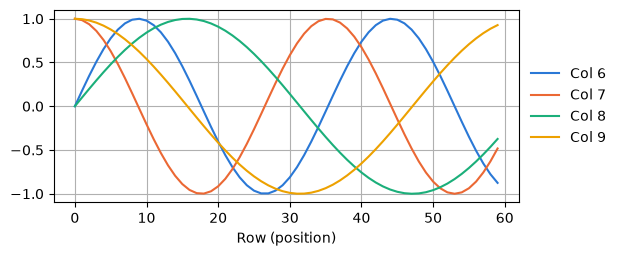

In [18]:
plt.figure(figsize=(6, 2.5))
plt.gca().set_prop_cycle(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100"])
# plt.plot draws one line per column of y, so y must be (num_steps, 4), not transposed.
plt.plot(torch.arange(num_steps), P[0, :, 6:10])
plt.xlabel("Row (position)")
plt.legend([f"Col {d}" for d in range(6, 10)], loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.grid()
plt.show()